# Exploratory Data Analysis

This notebook explores the synthetic student dataset before model training: understanding its structure, variable distributions, and relationships with the target variable.

**Steps:**
1. Load and inspect the dataset
2. Summary statistics
3. Feature distributions
4. Relationship with the target variable
5. Correlation analysis and key insights

In [2]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'{x:.2f}')

## 1. Load and inspect the dataset

First we load the generated CSV and check its basic structure.

In [3]:
data_path = Path("../data/students_dataset.csv")
df = pd.read_csv(data_path)

print(f'Dataset shape: {df.shape}')
display(df.head())
print('\nMissing values:')
print(df.isna().sum())
print('\nTarget distribution:')
print(df['at_risk'].value_counts().sort_index())

Dataset shape: (1000, 9)


,student_id,study_time_weekly,absences,sleep_hours,stress_level,parental_support,tutoring,extracurricular,at_risk
0,1,19.20,0,8.20,4,1,0,0,0
1,2,22.20,17,3.60,7,0,0,0,1
2,3,7.00,19,3.20,4,4,1,0,1
3,4,17.70,0,8.30,3,3,1,1,0
4,5,6.50,10,3.70,7,0,1,1,1



Missing values:
student_id           0
study_time_weekly    0
absences             0
sleep_hours          0
stress_level         0
parental_support     0
tutoring             0
extracurricular      0
at_risk              0
dtype: int64

Target distribution:
at_risk
0    659
1    341
Name: count, dtype: int64


## 2. Summary statistics

We inspect central tendency and spread for the numerical features.

In [4]:
numeric_cols = [
    'study_time_weekly',
    'absences',
    'sleep_hours',
    'stress_level',
    'parental_support',
    'tutoring',
    'extracurricular',
]

df[numeric_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
study_time_weekly,1000.00,15.03,8.69,0.00,7.47,15.10,22.40,30.00
absences,1000.00,10.23,5.89,0.00,5.00,10.00,15.00,20.00
sleep_hours,1000.00,6.47,2.02,3.00,4.70,6.40,8.20,10.00
stress_level,1000.00,5.60,2.89,1.00,3.00,6.00,8.00,10.00
parental_support,1000.00,2.03,1.40,0.00,1.00,2.00,3.00,4.00
tutoring,1000.00,0.48,0.50,0.00,0.00,0.00,1.00,1.00
extracurricular,1000.00,0.50,0.50,0.00,0.00,1.00,1.00,1.00


## 3. Feature distributions

Histograms help us check the shape of each numerical variable and spot obvious skew or outliers.

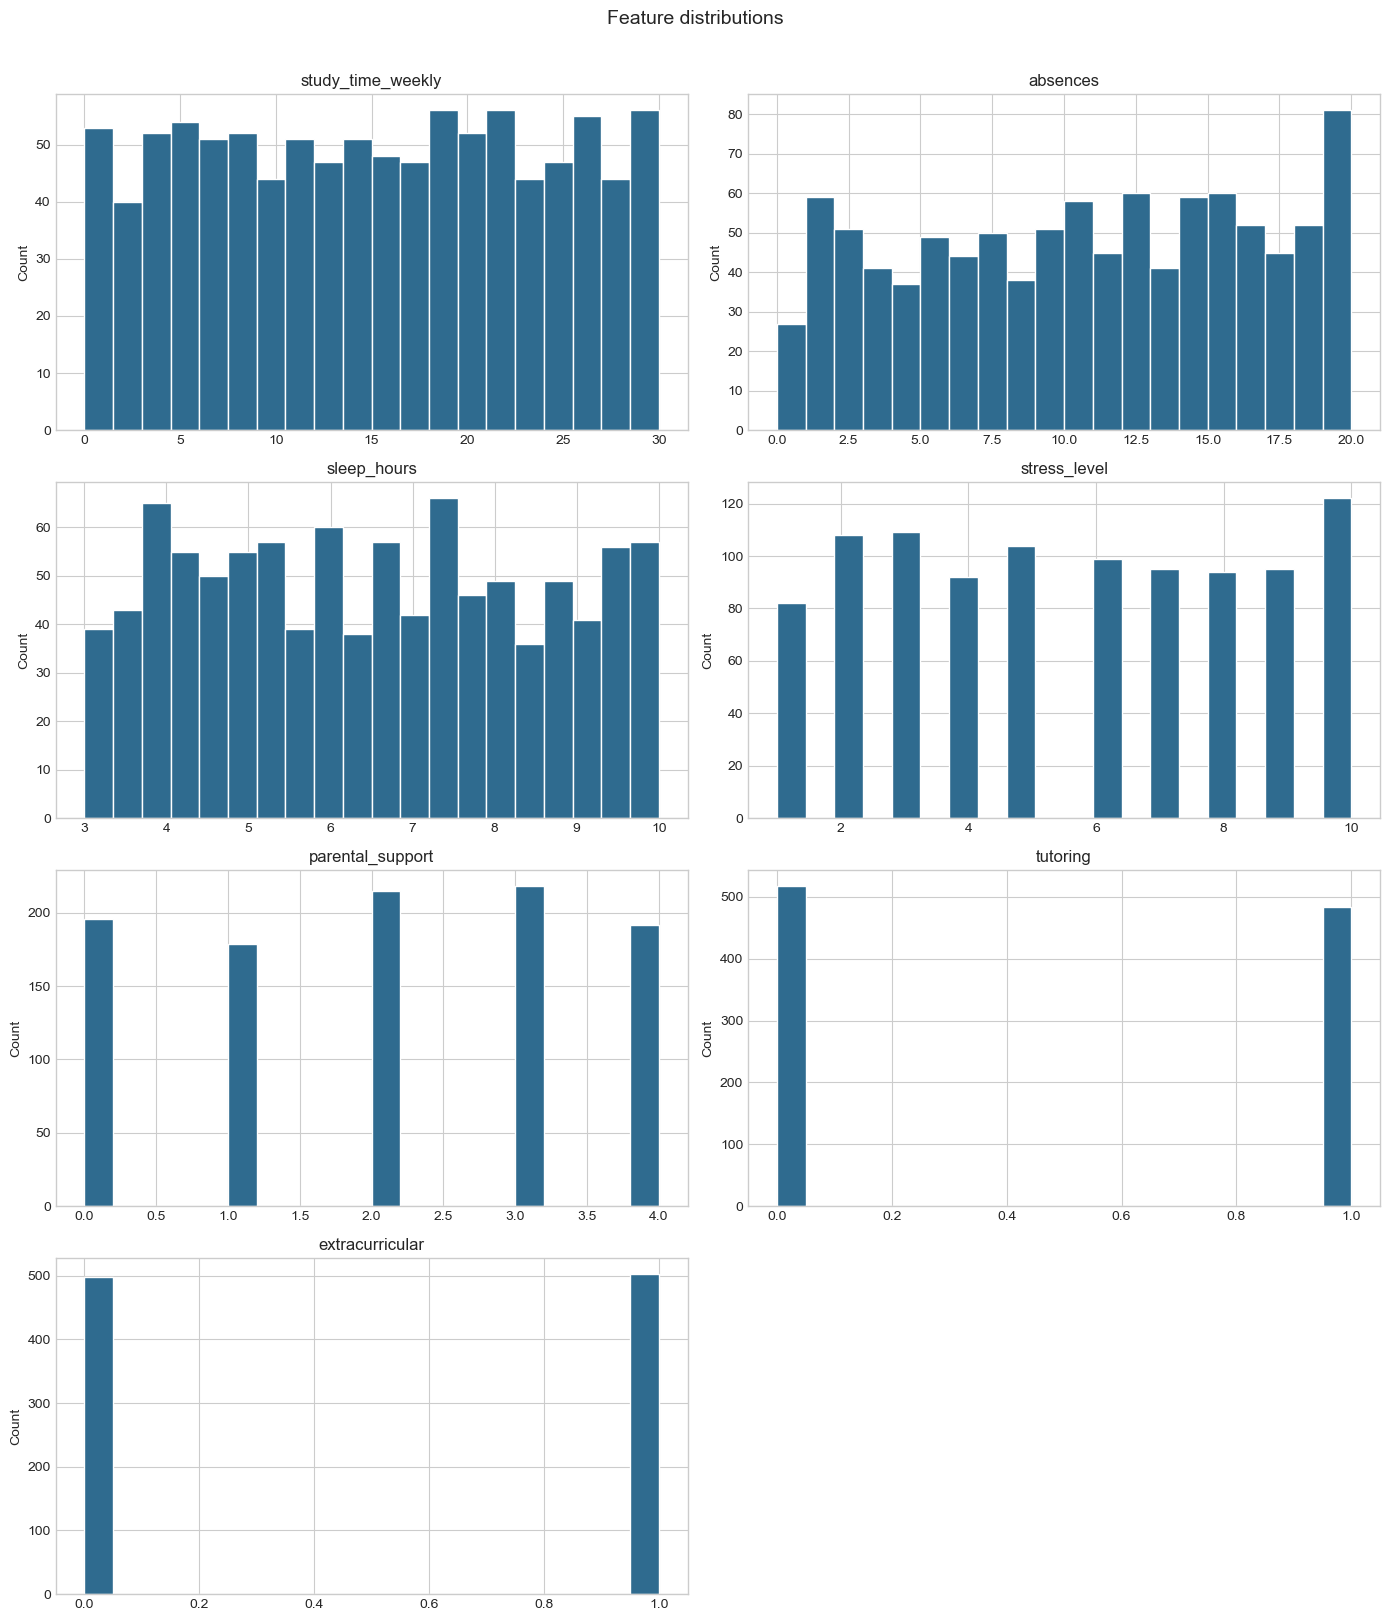

In [5]:
fig, axes = plt.subplots(4, 2, figsize=(14, 16))
axes = axes.ravel()

for idx, col in enumerate(numeric_cols):
    axes[idx].hist(df[col], bins=20, color='#2f6b8f', edgecolor='white')
    axes[idx].set_title(col)
    axes[idx].set_ylabel('Count')

fig.delaxes(axes[-1])
fig.suptitle('Feature distributions', fontsize=14, y=1.01)
fig.tight_layout()
plt.show()

## 4. Relationship with the target

We compare the main features against the target to see which variables separate the classes better.

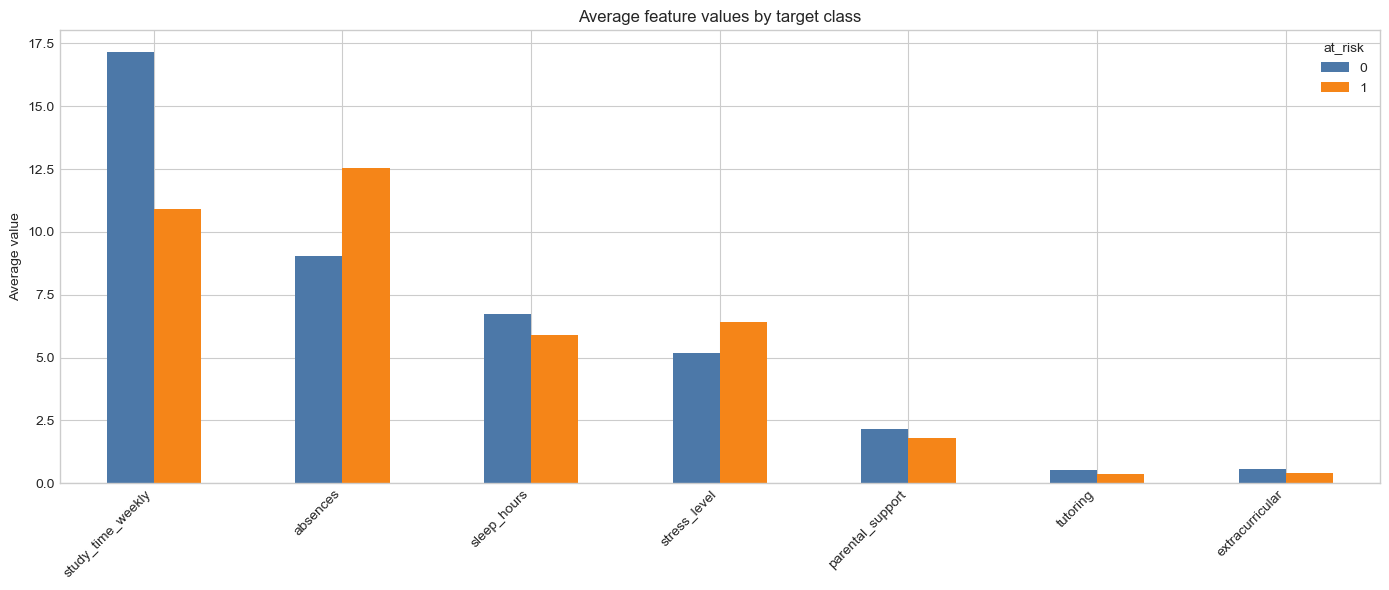

In [6]:
target_means = df.groupby('at_risk')[numeric_cols].mean().T

a = target_means.plot(kind='bar', figsize=(14, 6), color=['#4c78a8', '#f58518'])
a.set_ylabel('Average value')
a.set_title('Average feature values by target class')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## 5. Correlation analysis and final insights

A correlation matrix helps us understand which variables move together and which are most linked to the target.

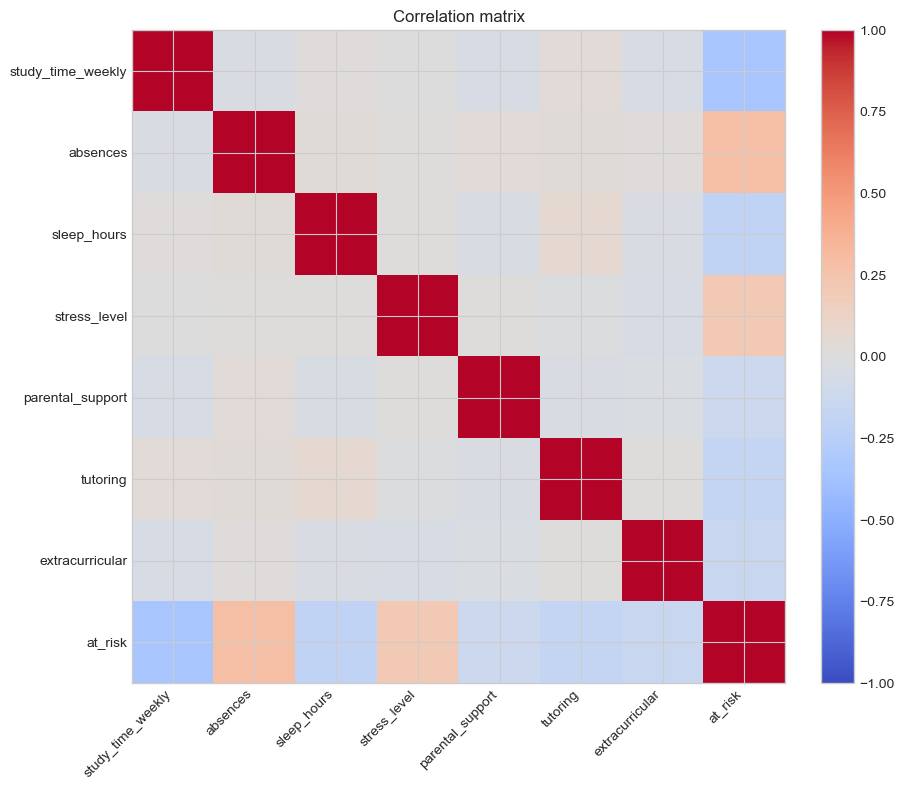

Correlations with at_risk (strongest first):
study_time_weekly   -0.34
absences             0.28
stress_level         0.21
sleep_hours         -0.20
tutoring            -0.18
extracurricular     -0.14
parental_support    -0.12

Key insights:
  - Strongest risk factor:       absences (corr=+0.28)
  - Strongest protective factor: study_time_weekly (corr=-0.34)
  - At-risk rate: 34.1% — class imbalance should be accounted for during model evaluation.


In [7]:
correlation_cols = numeric_cols + ['at_risk']
corr = df[correlation_cols].corr()

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns)))
ax.set_yticks(range(len(corr.index)))
ax.set_xticklabels(corr.columns, rotation=45, ha='right')
ax.set_yticklabels(corr.index)
ax.set_title('Correlation matrix')
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

at_risk_corr = corr['at_risk'].drop('at_risk').sort_values(key=lambda s: s.abs(), ascending=False)
print('Correlations with at_risk (strongest first):')
print(at_risk_corr.to_string())

print('\nKey insights:')
top_pos = at_risk_corr[at_risk_corr > 0].index[0]
top_neg = at_risk_corr[at_risk_corr < 0].index[0]
at_risk_rate = df['at_risk'].mean()
print(f'  - Strongest risk factor:       {top_pos} (corr={at_risk_corr[top_pos]:+.2f})')
print(f'  - Strongest protective factor: {top_neg} (corr={at_risk_corr[top_neg]:+.2f})')
print(f'  - At-risk rate: {at_risk_rate:.1%} — class imbalance should be accounted for during model evaluation.')